In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

r = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")
print(r.shape, meta.shape)
r.head()

(1340000, 5) (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [2]:
y = (r.groupby("timestamp")
       .agg(active_vm_count=("vm_id", "nunique"),
            aggregate_cpu_utilization=("avg_cpu", "mean"))
       .sort_index())

y_train = y.iloc[:110]   # first 110 timestamps
y_hold  = y.iloc[110:]   # last 24: do NOT use for fitting, tuning or choosing models
print(len(y_train), len(y_hold))
y_train.describe()

110 24


,active_vm_count,aggregate_cpu_utilization
count,110.0,110.000000
mean,10000.0,9.414089
std,0.0,0.193568
min,10000.0,9.111634
25%,10000.0,9.288952
50%,10000.0,9.378121
75%,10000.0,9.507673
max,10000.0,9.912175


In [3]:
print("duplicates (vm, time):", r.duplicated(["vm_id", "timestamp"]).sum())
print("missing values:\n", r.isna().sum())
print("time steps:", pd.Series(np.diff(sorted(r.timestamp.unique()))).value_counts().to_dict())
print("readings per VM:", r.groupby("vm_id").size().value_counts().to_dict())
print("avg_cpu range:", r.avg_cpu.min(), r.avg_cpu.max())

duplicates (vm, time): 0
missing values:
 timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64
time steps: {300: 133}
readings per VM: {134: 10000}
avg_cpu range: 0.0071589216268651 99.48802665399457


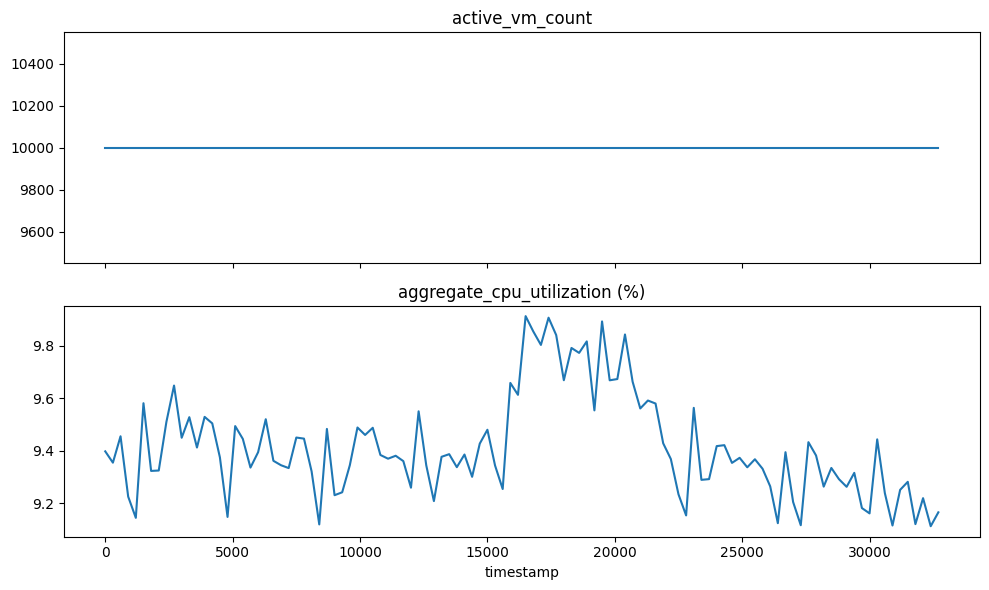

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
y_train.active_vm_count.plot(ax=ax[0], title="active_vm_count")
y_train.aggregate_cpu_utilization.plot(ax=ax[1], title="aggregate_cpu_utilization (%)")
plt.tight_layout()

count    10000.000000
mean         9.414089
std         13.051504
min          0.007345
25%          2.869327
50%          5.501660
75%          9.972827
max         99.272951
Name: avg_cpu, dtype: float64
0.50     5.501660
0.90    19.739861
0.99    79.623001
Name: avg_cpu, dtype: float64
share of total CPU from the top 10% of VMs: 0.435


<Axes: title={'center': 'Mean avg_cpu per VM (log count)'}, ylabel='Frequency'>

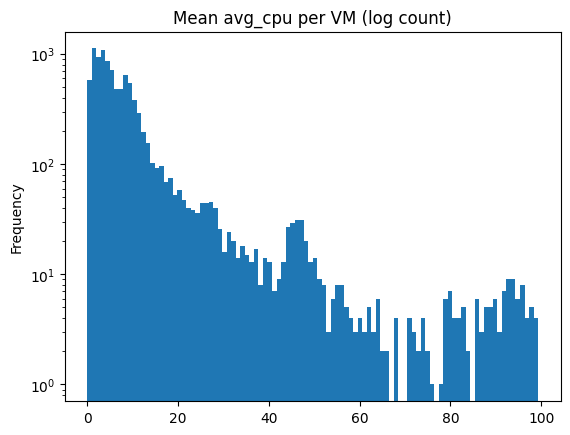

In [5]:
train_ts = y_train.index
rt = r[r.timestamp.isin(train_ts)]

vm_mean = rt.groupby("vm_id").avg_cpu.mean()
print(vm_mean.describe())
print(vm_mean.quantile([.5, .9, .99]))
top10 = vm_mean.sort_values(ascending=False).head(1000).sum() / vm_mean.sum()
print("share of total CPU from the top 10% of VMs:", round(top10, 3))
vm_mean.plot.hist(bins=100, log=True, title="Mean avg_cpu per VM (log count)")

                    count       mean    median        std
vm_category                                              
Delay-insensitive  679800   8.257266  5.160160  12.036259
Interactive        340010  11.505150  5.295715  16.950810
Unknown             80190  10.354689  3.415575  17.837379


<Axes: title={'center': 'Mean CPU by VM category'}, xlabel='timestamp'>

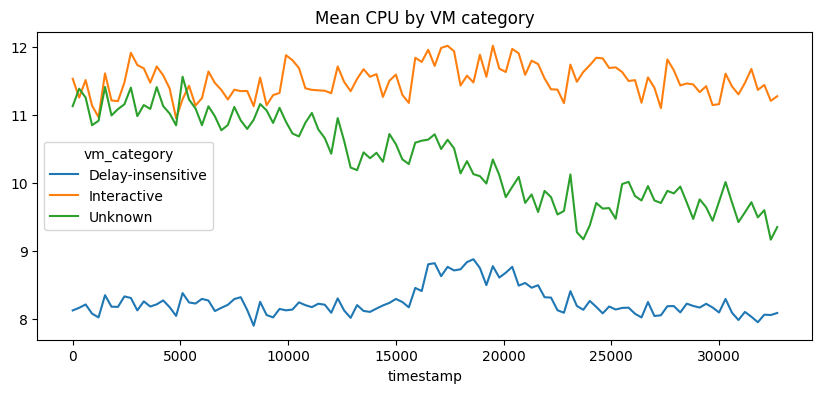

In [6]:
m = meta[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]]
rt = rt.merge(m, on="vm_id")

print(rt.groupby("vm_category").avg_cpu.agg(["count", "mean", "median", "std"]))
seg = rt.groupby(["timestamp", "vm_category"]).avg_cpu.mean().unstack()
seg.plot(figsize=(10, 4), title="Mean CPU by VM category")

In [7]:
s = y_train.aggregate_cpu_utilization
for lag in [1, 2, 3, 6, 12, 24]:
    print(lag, round(s.autocorr(lag), 3))

1 0.667
2 0.606
3 0.681
6 0.477
12 0.367
24 -0.026
